# Quadwind · один ноутбук для защиты

**От «дрон ничего не умеет» до одного шага RPPO.** Показываем всё в одном месте, по порядку:

| № | Что увидит аудитория | Где |
|---|---|---|
| 1 | Ранний и обученный агент в одинаковых условиях | раздел 1 |
| 2 | Включили постоянный боковой ветер и оставили его | раздел 2 |
| 3 | Ветер плавно нарастает 0 → 3 м/с за 3 с и держится | раздел 3 |
| 4 | Три наблюдения → награды → GAE → PPO loss → шаг Adam → прогнозы до/после | раздел 4 |
| 5 | Параметры обучения, кривая валидации, RPPO рядом с PID | раздел 5 |

**Цель защиты:** показать, как дрон учится удерживать точку при скрытом ветре, и объяснить на трёх переходах, как одно обновление Recurrent PPO меняет политику и оценку ценности.

**Как читать код.** Ноутбук вызывает те же функции, что и собственный тренер проекта: [`native_rollout.py`](../quadwind/native_rollout.py) (сбор траектории, GAE, последовательные минибатчи), [`native_policy.py`](../quadwind/native_policy.py) (актор, критик, PPO loss, шаг оптимизатора), [`native_training.py`](../quadwind/native_training.py) (цикл обучения), [`wind.py`](../quadwind/wind.py) и [`conditions.py`](../quadwind/conditions.py) (сценарии ветра).

```python
rollout = collector.collect(3, gamma, gae_lambda)
batch = next(rollout.minibatches(3, 3, rng))
loss = ppo_loss(policy, batch)
optimizer_step(policy, optimizer, loss)
```

**Офлайн.** Все выводы, графики и встроенное видео сохранены прямо в этом `.ipynb`. При открытии обучение **не запускается**: ноутбук читает готовые чекпоинты, CSV и MP4 по относительным путям. Выполните **Restart Kernel and Run All Cells** из корня проекта (или из `notebook/`). Русский разбор с формулами — в [`docs/rppo_one_update_ru.html`](../docs/rppo_one_update_ru.html).

In [1]:
from pathlib import Path
from types import SimpleNamespace
import sys

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Video

# Jupyter может стартовать из корня проекта или из notebook/.
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "quadwind").is_dir())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from quadwind.native_policy import NativeActorCritic, optimizer_step, ppo_loss
from quadwind.native_rollout import RolloutCollector
from quadwind.training import load_model, build_space
from quadwind.env import EnvConfig
from quadwind.evaluation import rollout
from quadwind.policies import SB3Policy
from quadwind.conditions import make_suite

torch.set_num_threads(1)
plt.rcParams.update({"figure.dpi": 110, "axes.unicode_minus": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
PAIRED_MP4 = root / "results" / "native_defense" / "before_after.mp4"
GUST_MP4 = root / "demo" / "hover.mp4"
print(f"Корень проекта: {root}")
for video in (PAIRED_MP4, GUST_MP4):
    print(f"Видео: {video.relative_to(root).as_posix()}, {video.stat().st_size / 1024:.0f} КБ")


# Один слот векторной среды: тот же интерфейс reset/step, что у Quadwind.
class ThreeDecisionHover:
    num_envs = 1
    wind = 0.2
    action_space = SimpleNamespace(low=np.array([-1.0]), high=np.array([1.0]))

    def observe(self):
        return np.array([[self.x, self.wind]], dtype=np.float32)

    def reset(self):
        self.x, self.t = 0.4, 0
        return self.observe()

    def step(self, commands):
        u = float(commands[0, 0])
        self.x += 0.2 * (u + self.wind)
        self.t += 1
        reward = 1.0 - abs(self.x) - 0.05 * u**2
        done = self.t == 3
        obs = self.observe()
        info = {"terminal_observation": obs[0].copy()} if done else {}
        if done:
            obs = self.reset()
        return obs, np.array([reward]), np.array([done]), [info]

Корень проекта: C:\Users\alfykls\Desktop\RL_PROJ\quadwind
Видео: results/native_defense/before_after.mp4, 155 КБ
Видео: demo/hover.mp4, 408 КБ


### Короткое видео полёта (встроено, без интернета)

**Основной ролик** — парная запись собственного PPO-LSTM: ранняя политика (**8 192 шага**) и выбранная на валидации (**3 000 000 шагов**) стартуют из одной точки при одном ветре и шуме. Ранняя уходит за 2 м и падает на **3,46 с**, обученная завершает 15-секундный полёт в **1,33 см** от цели. Это те же цифры, что посчитает раздел 1 ниже.

[`results/native_defense/before_after.mp4`](../results/native_defense/before_after.mp4)

<video src="../results/native_defense/before_after.mp4" width="640" controls preload="metadata"></video>

**Дополнительно:** [`demo/hover.mp4`](../demo/hover.mp4) — обученная RPPO и настроенный PID встречают порыв ветра на 6-й секунде.

Оба ролика продублированы ниже в base64 прямо в выводе ячейки, поэтому показ работает офлайн. Если проигрыватель не отобразился, откройте MP4 отдельным файлом.

In [2]:
for video, caption in ((PAIRED_MP4, "Ранняя и обученная политики в одинаковых условиях"),
                      (GUST_MP4, "Обученная RPPO и PID: порыв ветра на 6-й секунде")):
    if video.is_file():
        display(HTML(f"<p style='color:#475d63'><b>{caption}</b> — "
                     f"<code>{video.relative_to(root).as_posix()}</code></p>"))
        # embed=True кодирует MP4 в base64 прямо в вывод ячейки — ролик едет с ноутбуком.
        display(Video(filename=str(video), embed=True, width=640))
    else:
        print("Видео не найдено:", video)

## 1. Ранний и обученный агент: в начале дрон ничего не может сделать

Две политики **из одного запуска собственного тренера** (`runs/native_defense/rppo_hover/seed_0`, сид обучения 0) летят из одной точки, с одним сидом, ветром и шумом. Разница только в числе шагов обучения.

| | Чекпоинт | Тренер | Шагов обучения |
|---|---|---|---|
| Ранний агент | `early_model.zip` | собственный RPPO (PyTorch, `native_training.py`) | **8 192** (один сбор) |
| Обученный агент | `best_model.zip` | тот же собственный RPPO | **3 000 000** (выбран на валидации) |

Условие взято из набора `research/probe`, эпизод 0 — **то же самое, что в парном видео выше** и в [`results/native_defense/paired_flights.csv`](../results/native_defense/paired_flights.csv). Ранняя политика после одного обновления ещё не умеет компенсировать снос: дрон уходит за 2 м и завершает эпизод аварией на 3,46 с. Обученная проходит все 15 с и заканчивает в 1,33 см от цели.

**Под каждым полётом на графике подписано число шагов обучения** — оно берётся прямо из чекпоинта (`model.num_timesteps`), а не захардкожено. Полный запуск с логами и тремя сидами описан в [`results/native_defense/summary.md`](../results/native_defense/summary.md).

In [3]:
NATIVE_RUN = root / "runs" / "native_defense" / "rppo_hover" / "seed_0"


# Загрузить ГОТОВЫЕ веса. Обучение здесь не запускается.
def load_agent(which, name):
    model, normalizer, cfg = load_model(NATIVE_RUN, which)
    steps = int(model.num_timesteps)          # число шагов берётся из самого чекпоинта
    pretty = f"{steps:,}".replace(",", " ")
    return dict(label=f"{name} · {pretty} шагов обучения", steps=steps,
                trainer="свой RPPO (PyTorch)", which=which, run=NATIVE_RUN, cfg=cfg,
                policy=SB3Policy(model, normalizer), env_cfg=EnvConfig.from_dict(cfg["env"]))


agents = {
    "ранний": load_agent("early", "Ранний агент"),
    "обученный": load_agent("best", "Обученный агент"),
}
# То же условие, что в results/native_defense/before_after.mp4 и paired_flights.csv.
condition = make_suite("probe", 1, space=build_space(agents["ранний"]["cfg"]),
                       namespace="research")[0]
flights = {name: rollout(a["policy"], a["env_cfg"], [condition]) for name, a in agents.items()}
print("Старт, сид " + "-".join(map(str, condition.seed)) +
      f" и ветер {condition.wind.speed:.2f} м/с одинаковы для обеих политик.")
print(f"Длина эпизода: {agents['ранний']['env_cfg'].episode_seconds:.0f} с, шаг управления 20 мс.")

Старт, сид 1511-3613290282-0 и ветер 0.80 м/с одинаковы для обеих политик.
Длина эпизода: 15 с, шаг управления 20 мс.


In [4]:
def flight_track(ro):
    L = int(ro.length[0])
    t = ro.t[:L]
    e = ro.data["pos_err"][:L, 0]                 # истинная ошибка позиции (L, 3)
    return t, e, np.linalg.norm(e, axis=1)


rows = []
for name, a in agents.items():
    t, e, dist = flight_track(flights[name])
    ro = flights[name]
    mean_cm = 100 * dist[t >= 2.0].mean() if (t >= 2.0).any() else 100 * dist.mean()
    rows.append({
        "Политика": a["label"], "Тренер": a["trainer"], "Шагов обучения": a["steps"],
        "Полёт, с": round(t[-1], 2),
        "Итог": "ПАДЕНИЕ (" + ro.crash_reason[0] + ")" if ro.crashed[0] else "удержал точку",
        "Ср. ошибка после 2 с, см": round(mean_cm, 1),
        "Макс. ошибка, см": round(100 * dist.max(), 1),
    })
display(pd.DataFrame(rows).set_index("Политика"))

,Тренер,Шагов обучения,"Полёт, с",Итог,"Ср. ошибка после 2 с, см","Макс. ошибка, см"
Политика,,,,,,
Ранний агент · 8 192 шагов обучения,свой RPPO (PyTorch),8192,3.46,ПАДЕНИЕ (distance),162.4,200.0
Обученный агент · 3 000 000 шагов обучения,свой RPPO (PyTorch),3000000,15.00,удержал точку,1.1,18.2


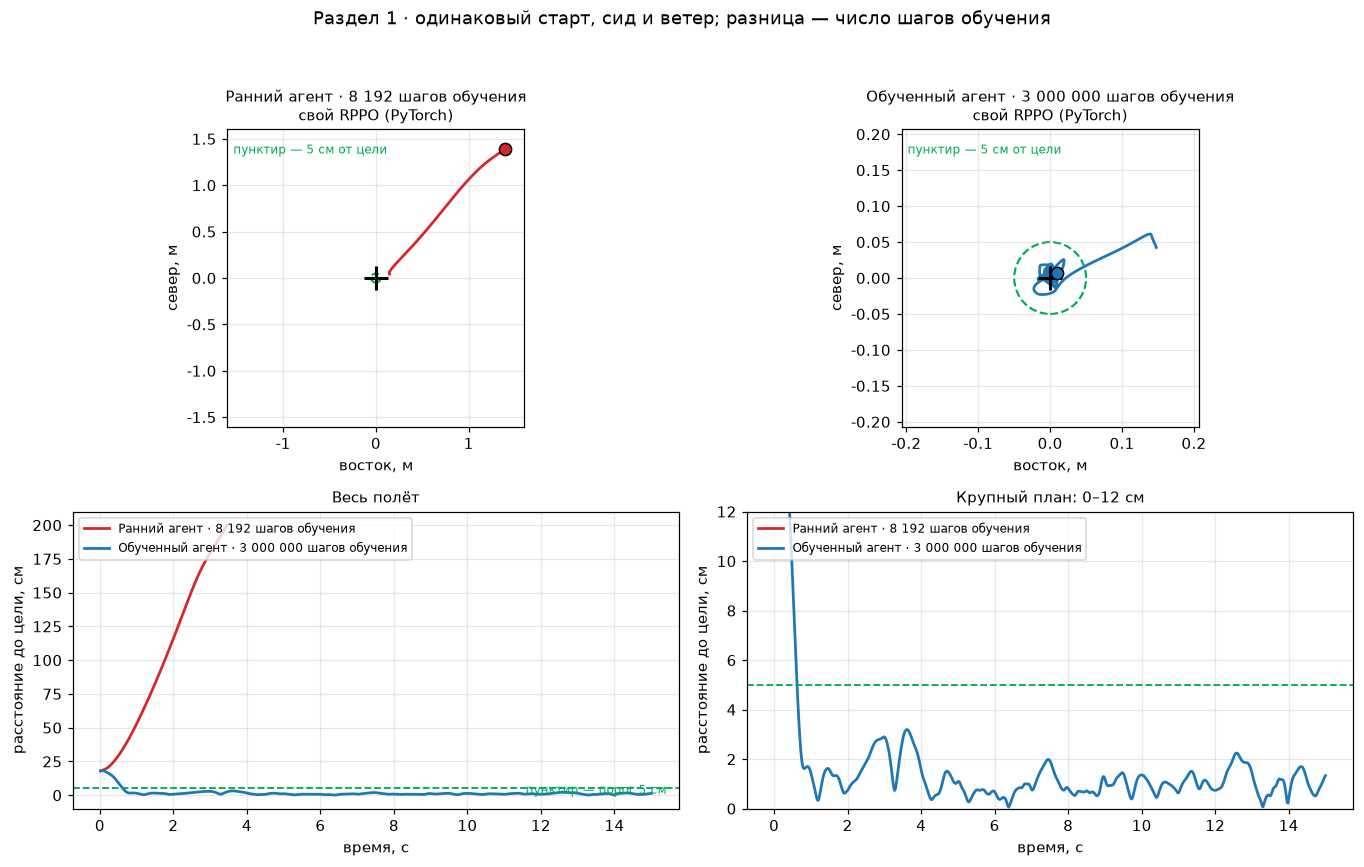

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8))
colors = {"ранний": "#d62728", "обученный": "#1f77b4"}

for col, name in enumerate(("ранний", "обученный")):
    a = agents[name]
    t, e, dist = flight_track(flights[name])
    ax = axes[0, col]
    ax.plot(e[:, 0], e[:, 1], color=colors[name], lw=1.8)
    ax.plot(0, 0, "+", color="k", ms=16, mew=2, label="цель")
    ax.add_patch(plt.Circle((0, 0), 0.05, fill=False, ls="--", color="#0a5", lw=1.4))
    ax.plot([e[-1, 0]], [e[-1, 1]], "o", color=colors[name], ms=8, mec="k")
    ax.set_aspect("equal")
    ax.set_title(a["label"] + "\n" + a["trainer"], fontsize=10)
    ax.set_xlabel("восток, м")
    ax.set_ylabel("север, м")
    lim = max(0.08, 1.15 * np.abs(e[:, :2]).max()) if name == "ранний" else \
          max(0.08, 1.4 * np.abs(e[:, :2]).max())
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.text(0.02, 0.95, "пунктир — 5 см от цели", transform=ax.transAxes,
            va="top", color="#0a5", fontsize=8)

for col, (ylim, title) in enumerate([(None, "Весь полёт"), ((0, 12), "Крупный план: 0–12 см")]):
    ax = axes[1, col]
    for name in ("ранний", "обученный"):
        t, e, dist = flight_track(flights[name])
        ax.plot(t, 100 * dist, color=colors[name], lw=1.8, label=agents[name]["label"])
    ax.axhline(5, ls="--", color="#0a5", lw=1.2)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("время, с")
    ax.set_ylabel("расстояние до цели, см")
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.legend(fontsize=8, loc="upper left")

axes[1, 0].text(0.98, 0.05, "пунктир — порог 5 см", transform=axes[1, 0].transAxes,
                ha="right", color="#0a5", fontsize=8)
fig.suptitle("Раздел 1 · одинаковый старт, сид и ветер; разница — число шагов обучения", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

## 2–3. Два ветровых опыта на общей оси времени

Оба опыта идут на **обученной политике собственного тренера** из раздела 1 (`best_model.zip`, 3 млн шагов). Дрон сначала спокойно висит в штиле, событие начинается на $t=5$ с, эпизод длится 15 с.

- **Раздел 2 — включаем постоянный ветер.** Используем уже существующий в проекте сценарий `step_gust` (`SCENARIO_SPACES` в `conditions.py`): ступенька бокового ветра 2,5 м/с в момент 5 с, дальше ветер **остаётся включённым** до конца полёта.
- **Раздел 3 — нарастающий ветер.** Новый сценарий `ramp_gust`, добавленный в `conditions.py`, и профиль `kind="ramp"` в `generate_wind()` (`wind.py`): скорость плавно растёт от 0 до 3 м/с за 3 секунды ($t\in[5,8]$ с) и затем держится на 3 м/с. Профиль проверен тестом `test_ramp_grows_linearly_then_holds`.

**Заранее выбранный критерий возврата:** ошибка позиции $\le 5$ см **непрерывно в течение 1 секунды** после пика отклонения. Если дрон вылетал за 5 см, а такого интервала нет — в таблице честно пишем «возврата не было». Если пик вообще не превысил 5 см, отдельно указываем «порог не превышался»: возврат в этом опыте не требовался.

Для обоих опытов выводим: пик отклонения (см и момент), время возврата (с) и остаточную ошибку (средняя ошибка за последние 3 с под продолжающимся ветром, см). Сверху каждого рисунка — скорость ветра, снизу — ошибка позиции, **общая ось времени**.

Для выбора ветра достаточно параметра `SCENARIO` и кнопки «Запустить сценарий» ниже; при **Run All** оба графика и таблица сохраняются сразу.

In [6]:
STEP_COND = make_suite("step_gust", n=1)[0]   # существующий сценарий проекта
RAMP_COND = make_suite("ramp_gust", n=1)[0]   # новый сценарий
SCENARIOS = {
    "step_gust": ("2. Включаем постоянный боковой ветер", STEP_COND, 5.0,
                  "ступенька 2,5 м/с на 5 с, ветер остаётся"),
    "ramp_gust": ("3. Нарастающий ветер 0 → 3 м/с за 3 с", RAMP_COND, 5.0,
                  "линейный рост до 3 м/с, затем 3 м/с"),
}
for key, (title, cond, t0, note) in SCENARIOS.items():
    ev = cond.wind.events[0]
    print(f"{key:10s} | {ev.kind:5s} на t={ev.time:.1f} с | |dw|={np.linalg.norm(ev.vec):.2f} м/с "
          f"| dur={ev.dur:.1f} с | {note}")

step_gust  | step  на t=5.0 с | |dw|=2.50 м/с | dur=1.0 с | ступенька 2,5 м/с на 5 с, ветер остаётся
ramp_gust  | ramp  на t=5.0 с | |dw|=3.00 м/с | dur=3.0 с | линейный рост до 3 м/с, затем 3 м/с


In [7]:
RETURN_RADIUS = 0.05    # м: 5 см
RETURN_HOLD = 1.0       # с: столько держаться внутри радиуса
TAIL_SECONDS = 3.0      # с: окно остаточной ошибки
EVENT_WINDOW = 8.0      # с: окно анализа после события


# Один прогон; ветер и ошибка берутся из ИСТИННЫХ траекторий, а не из шумных датчиков.
def wind_experiment(cond, agent):
    ro = rollout(agent["policy"], agent["env_cfg"], [cond])
    L = int(ro.length[0])
    t = ro.t[:L]
    dist = np.linalg.norm(ro.data["pos_err"][:L, 0], axis=1)
    speed = np.linalg.norm(ro.data["wind"][:L, 0, :2], axis=1)
    return dict(t=t, dist=dist, speed=speed, crashed=bool(ro.crashed[0]),
                reason=ro.crash_reason[0])


def response_metrics(exp, t_event):
    t, d = exp["t"], exp["dist"]
    post = (t >= t_event) & (t <= t_event + EVENT_WINDOW)
    tp, dp = t[post], d[post]
    k_peak = int(np.argmax(dp))
    peak_cm, peak_t = 100 * dp[k_peak], tp[k_peak]
    # Первый интервал длиной RETURN_HOLD, ВСЁ время внутри радиуса, не раньше пика.
    dt = float(np.median(np.diff(t)))
    need = max(1, int(np.ceil(RETURN_HOLD / dt)))
    inside = (d <= RETURN_RADIUS).astype(int)
    cum = np.concatenate(([0], np.cumsum(inside)))
    full = cum[need:] - cum[:-need]
    starts = np.flatnonzero(full == need)
    starts = starts[t[starts] >= peak_t]
    return_s = float(t[starts[0]] - t_event) if starts.size else None
    tail = t >= t[-1] - TAIL_SECONDS
    residual_cm = 100 * float(d[tail].mean())
    exceeded = bool(peak_cm > 100 * RETURN_RADIUS)
    return dict(peak_cm=float(peak_cm), peak_t=float(peak_t), return_s=return_s,
                residual_cm=residual_cm, exceeded=exceeded)

In [8]:
def plot_experiment(key, exp, m):
    title, cond, t_event, note = SCENARIOS[key]
    fig, (ax_w, ax_e) = plt.subplots(2, 1, figsize=(9.5, 5.2), sharex=True,
                                     gridspec_kw={"height_ratios": [1, 1.5]})
    ax_w.plot(exp["t"], exp["speed"], color="#0a5", lw=2.0)
    ax_w.set_ylabel("скорость ветра, м/с")
    ax_w.set_ylim(-0.1, max(3.6, 1.15 * exp["speed"].max()))
    ax_w.set_title(title + "\n" + note, fontsize=11)

    ax_e.plot(exp["t"], 100 * exp["dist"], color="#1f77b4", lw=1.8, label="ошибка позиции")
    ax_e.axhline(100 * RETURN_RADIUS, ls="--", color="#d62728", lw=1.2, label="порог 5 см")
    ax_e.plot([m["peak_t"]], [m["peak_cm"]], "v", color="#d62728", ms=9)
    ax_e.annotate(f"пик {m['peak_cm']:.1f} см", (m["peak_t"], m["peak_cm"]),
                  xytext=(8, 8), textcoords="offset points", fontsize=9, color="#d62728")
    if not m["exceeded"]:
        ax_e.text(0.99, 0.92, "порог 5 см не превышался", transform=ax_e.transAxes, ha="right",
                  color="#005b53", fontsize=10, weight="bold")
    elif m["return_s"] is not None:
        t_ret = t_event + m["return_s"]
        ax_e.axvspan(t_ret, t_ret + RETURN_HOLD, color="#bdedd3", alpha=0.6)
        ax_e.axvline(t_ret, ls="-.", color="#005b53", lw=1.2)
        ax_e.annotate(f"возврат через {m['return_s']:.2f} с", (t_ret, 2),
                      xytext=(8, 0), textcoords="offset points", fontsize=9, color="#005b53")
    else:
        ax_e.text(0.99, 0.92, "возврата не было", transform=ax_e.transAxes, ha="right",
                  color="#d62728", fontsize=10, weight="bold")
    for ax in (ax_w, ax_e):
        ax.axvspan(t_event, exp["t"][-1], color="#f0f0f0", alpha=0.4, zorder=0)
        ax.axvline(t_event, ls=":", color="#738298", lw=1.2)
    ax_w.annotate("ветер включён →", (t_event, ax_w.get_ylim()[1] * 0.72),
                  xytext=(8, 0), textcoords="offset points", fontsize=9, color="#44546b")
    ax_e.set_xlabel("время, с (общая ось для ветра и ошибки)")
    ax_e.set_ylabel("расстояние до цели, см")
    ax_e.set_ylim(bottom=0)
    ax_e.legend(fontsize=9, loc="upper right")
    fig.tight_layout()
    plt.show()

Критерий возврата: ошибка ≤ 5 см непрерывно 1,0 с после пика отклонения.


,Профиль ветра,"Пик отклонения, см","Момент пика, с","Время возврата, с","Остаточная ошибка, см"
Опыт,,,,,
2. Включаем постоянный боковой ветер,"ступенька 2,5 м/с на 5 с, ветер остаётся",5.1,5.54,0.64,1.5
3. Нарастающий ветер 0 → 3 м/с за 3 с,"линейный рост до 3 м/с, затем 3 м/с",1.8,7.02,порог не превышался,0.7



2. Включаем постоянный боковой ветер  |  критерий: ≤ 5 см непрерывно 1,0 с после пика


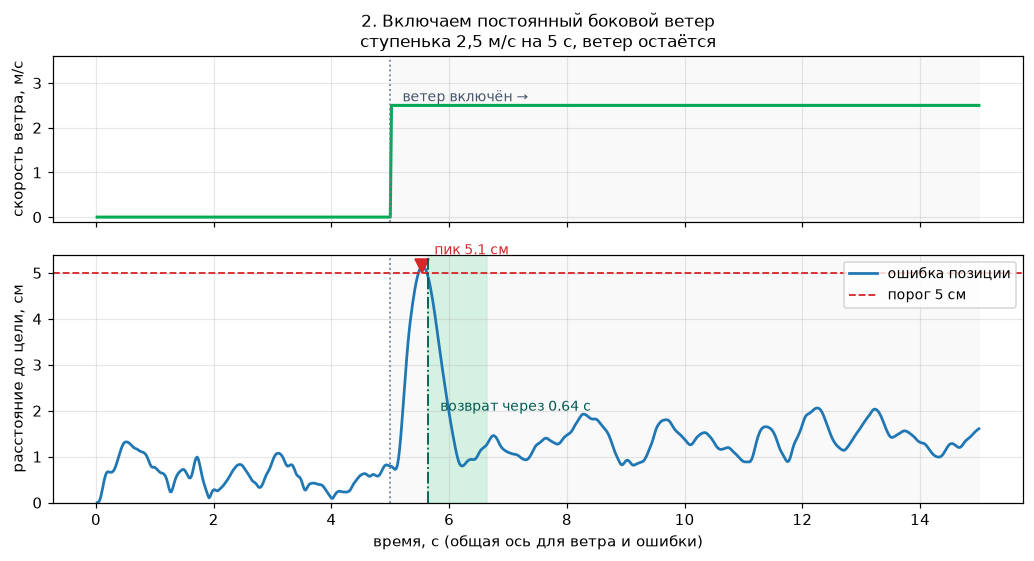

пик 5.1 см на t=5.54 с · время возврата: 0.64 с · остаточная ошибка 1.5 см

3. Нарастающий ветер 0 → 3 м/с за 3 с  |  критерий: ≤ 5 см непрерывно 1,0 с после пика


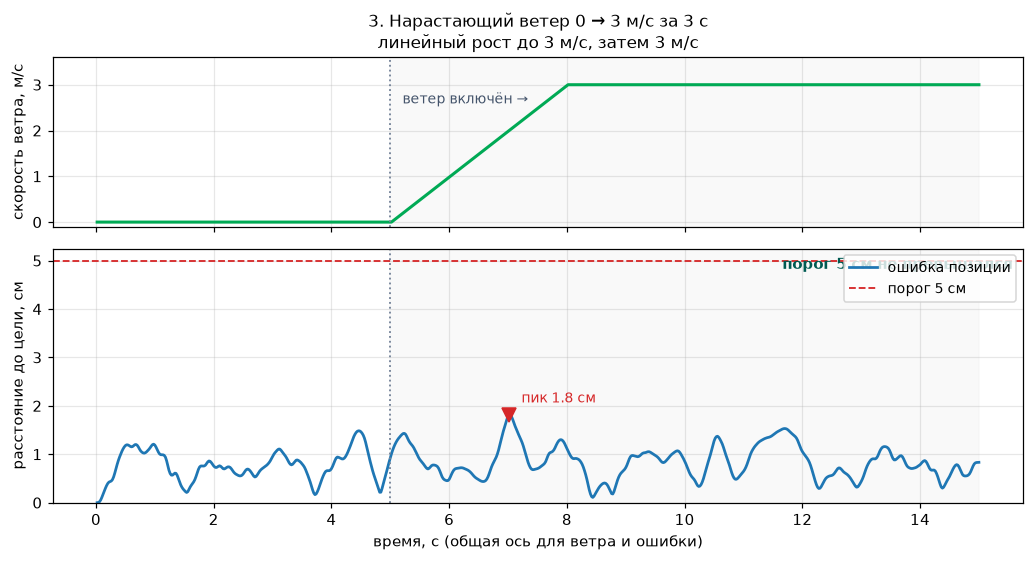

пик 1.8 см на t=7.02 с · время возврата: порог не превышался · остаточная ошибка 0.7 см


Output()

In [9]:
SCENARIO = "оба"   # ← параметр сценария: "step_gust", "ramp_gust" или "оба"

EXPERIMENTS = {key: wind_experiment(cond, agents["обученный"])
               for key, (_, cond, _, _) in SCENARIOS.items()}
METRICS = {key: response_metrics(EXPERIMENTS[key], t0)
           for key, (_, _, t0, _) in SCENARIOS.items()}


def return_text(m):
    if not m["exceeded"]:
        return "порог не превышался"
    if m["return_s"] is None:
        return "возврата не было"
    return round(m["return_s"], 2)


def summary_table():
    rows = []
    for key, (title, cond, t0, note) in SCENARIOS.items():
        m = METRICS[key]
        ret = return_text(m)
        rows.append({
            "Опыт": title, "Профиль ветра": note,
            "Пик отклонения, см": round(m["peak_cm"], 1),
            "Момент пика, с": round(m["peak_t"], 2),
            "Время возврата, с": ret,
            "Остаточная ошибка, см": round(m["residual_cm"], 1),
        })
    return pd.DataFrame(rows).set_index("Опыт")


def show(choice):
    keys = list(SCENARIOS) if choice == "оба" else [choice]
    for key in keys:
        title, _, t0, _ = SCENARIOS[key]
        m = METRICS[key]
        print(f"\n{title}  |  критерий: ≤ 5 см непрерывно 1,0 с после пика")
        plot_experiment(key, EXPERIMENTS[key], m)
        ret = "порог не превышался" if not m["exceeded"] else (
            "не было" if m["return_s"] is None else f"{m['return_s']:.2f} с")
        print(f"пик {m['peak_cm']:.1f} см на t={m['peak_t']:.2f} с · "
              f"время возврата: {ret} · остаточная ошибка {m['residual_cm']:.1f} см")


# При «Run All» таблица и ОБА графика сразу сохраняются в выводах ноутбука (офлайн).
print("Критерий возврата: ошибка ≤ 5 см непрерывно 1,0 с после пика отклонения.")
display(summary_table())
show("оба")

# Для живого показа: параметр SCENARIO выше И кнопка запуска.
try:
    import ipywidgets as widgets
    dd = widgets.Dropdown(options=[("оба сценария", "оба"),
                                   ("2 · постоянный ветер", "step_gust"),
                                   ("3 · нарастающий ветер", "ramp_gust")],
                          value="оба", description="Ветер:")
    btn = widgets.Button(description="Запустить сценарий", button_style="primary")
    out = widgets.Output()

    def _on_click(_button):
        with out:
            out.clear_output(wait=True)
            show(dd.value)

    btn.on_click(_on_click)
    display(widgets.HBox([dd, btn]), out)
except Exception as exc:                      # без ipywidgets всё равно работает
    print(f"Кнопка недоступна ({exc}); достаточно параметра SCENARIO и повторного запуска ячейки.")

## 4. Одно обновление RPPO: разбор по коду

Здесь мы **проходимся по коду** собственного тренера на крошечной задаче, где каждое число можно проверить на калькуляторе. Используются те же классы, что и в полном обучении: `NativeActorCritic`, `RolloutCollector`, `ppo_loss`, `optimizer_step`.

Порядок показа: три наблюдения подряд → действия и награды → GAE → PPO loss → один шаг оптимизатора → прогнозы до и после.

### 4.1 Что видит агент

Задача на три решения начинается в $x=0{,}4$ от цели $x=0$. Постоянный ветер $w=0{,}2$ толкает в сторону $+x$. Актор видит только $x$, критик во время обучения видит и $x$, и $w$ (в полной модели — 13 привилегированных признаков симулятора). Отрицательная команда толкает против ветра. Команда в симулятор $u=\mathrm{clip}(a,-1,1)$, где $a$ — выборка из гауссовой политики. За один шаг:

$$x_{t+1}=x_t+0{,}2(u_t+w),\qquad r_t=1-|x_{t+1}|-0{,}05 u_t^2.$$

Третья награда завершает конечную задачу, поэтому продолжение равно нулю. В полном Quadwind при обрыве по лимиту времени коллектор берёт оценку критика на последнем наблюдении перед сбросом.

### 4.2 Читаемая LSTM

В обеих сетях по одной ячейке памяти. У актора веса и смещения входных ворот, ворот забывания и выходных ворот равны нулю, поэтому $i=f=o=0{,}5$. Ненулевые только веса кандидата:

$$g_t=\tanh(x_t+0{,}5h_{t-1}),\qquad c_t=0{,}5c_{t-1}+0{,}5g_t,\qquad h_t=0{,}5\tanh(c_t),$$
$$\mu_t=W_\pi h_t+b_\pi,\qquad \sigma=e^{-1},\qquad V_t=0{,}8h_t^{V}+0{,}1.$$

Начальные значения: $W_\pi=-0{,}5$, $b_\pi=0{,}02$. Так один проход вперёд проверяется вручную.

In [10]:
policy = NativeActorCritic(obs_dim=2, actor_dim=1, action_dim=1, hidden_size=1,
                           actor_layers=(), critic_layers=(), log_std_init=-1.0)
with torch.no_grad():
    for parameter in policy.parameters():
        parameter.zero_()
    # Порядок ворот в PyTorch: input, forget, candidate, output.
    for lstm in (policy.actor_lstm, policy.critic_lstm):
        lstm.weight_ih_l0[2, 0] = 1.0
        lstm.weight_hh_l0[2, 0] = 0.5
    policy.critic_lstm.weight_ih_l0[2, 1] = 0.5
    policy.actor_head.weight.fill_(-0.5)
    policy.actor_head.bias.fill_(0.02)
    policy.critic_head.weight.fill_(0.8)
    policy.critic_head.bias.fill_(0.1)
    policy.log_std.fill_(-1.0)

first_c = 0.5 * np.tanh(0.4)
first_h = 0.5 * np.tanh(first_c)
print(f"Первое наблюдение x=0,4, нулевая входящая память: c={first_c:.5f}, "
      f"h={first_h:.5f}, средняя команда={-0.5*first_h + 0.02:.5f}")

Первое наблюдение x=0,4, нулевая входящая память: c=0.18997, h=0.09386, средняя команда=-0.02693


### 4.3 Собираем три решения по порядку

`RolloutCollector.collect()` на каждом шаге один раз фиксирует наблюдение, выборку действия, награду, старую оценку критика, старый логарифм плотности и **входящую память**. Первая строка начинается с нулевой памяти, каждая следующая получает память предыдущей. **Веса при полёте не меняются** — меняются положение дрона и состояния $(h,c)$ обеих LSTM. В таблице показана исходящая память актора после чтения $x_t$. В симулятор уходит ограниченная команда $u$, а PPO оценивает исходную гауссову выборку $a$.

In [11]:
gamma, gae_lambda, clip_range = 0.99, 0.95, 0.2
torch.manual_seed(7)
collector = RolloutCollector(ThreeDecisionHover(), policy)
rollout = collector.collect(3, gamma, gae_lambda)
rng = np.random.default_rng(0)
batch = next(rollout.minibatches(batch_size=3, sequence_length=3, rng=rng))
assert batch.mask.all() and batch.episode_starts[:, 0].tolist() == [True, False, False]

# Проходим по траектории ещё раз, чтобы показать исходящую память актора.
actor_hidden = []
state = batch.initial_state
with torch.no_grad():
    print(" t       x       c       h      mu       a       r   V_old  logp_old")
    for t in range(3):
        dist, value, state = policy(batch.obs[t:t+1], state, batch.episode_starts[t:t+1])
        h, c = state[0].item(), state[1].item()
        actor_hidden.append(h)
        print(f"{t+1:2} {batch.obs[t,0,0]:7.4f} {c:7.4f} {h:7.4f} "
              f"{dist.mean.item():7.4f} {batch.actions[t,0,0]:7.4f} "
              f"{rollout.rewards[t,0]:7.4f} {value.item():7.4f} {batch.old_log_prob[t,0]:9.4f}")

    mu_old = policy(batch.obs, batch.initial_state, batch.episode_starts)[0].mean.detach().clone()
    mu_reset = policy(batch.obs[1:2], policy.initial_state(1), batch.episode_starts[0:1])[0].mean
    print(f"На том же втором наблюдении: средняя команда с памятью {mu_old[1].item():.5f}, "
          f"после принудительного сброса памяти {mu_reset.item():.5f}.")
    assert not torch.allclose(mu_old[1], mu_reset[0])
np.testing.assert_allclose(actor_hidden[0], first_h, atol=1e-6)

# Проводим первую выборку от распределения до награды.
a = batch.actions[0, 0, 0].item()
u = np.clip(a, -1, 1)
x2 = 0.4 + 0.2 * (u + ThreeDecisionHover.wind)
r1 = 1 - abs(x2) - 0.05 * u**2
sigma = np.exp(-1.)
logp1 = -0.5 * ((a - mu_old[0].item()) / sigma)**2 - np.log(sigma * np.sqrt(2 * np.pi))
np.testing.assert_allclose([x2, r1, logp1],
                           [batch.obs[1, 0, 0], rollout.rewards[0, 0], batch.old_log_prob[0, 0]], atol=1e-6)
print(f"Выборка a={a:.4f}, команда u={u:.4f}, следующее x={x2:.4f}, "
      f"награда={r1:.4f}, log плотности a={logp1:.4f}")

 t       x       c       h      mu       a       r   V_old  logp_old
 1  0.4000  0.1900  0.0939 -0.0269 -0.0809  0.5759  0.1908    0.0703
 2  0.4238  0.3144  0.1522 -0.0561  0.2331  0.4868  0.2441   -0.2279
 3  0.5104  0.4209  0.1988 -0.0794  0.2689  0.3922  0.2820   -0.3672
На том же втором наблюдении: средняя команда с памятью -0.05611, после принудительного сброса памяти -0.02936.
Выборка a=-0.0809, команда u=-0.0809, следующее x=0.4238, награда=0.5759, log плотности a=0.0703


### 4.4 Считаем от конца к началу: GAE и цели критика

$V_t$ — оценка критика до обновления. Ошибка прогноза на одном шаге $\delta_t=r_t+\gamma V_{t+1}-V_t$, преимущество накапливается назад: $A_t=\delta_t+\gamma\lambda A_{t+1}$. На последнем шаге $V_4=A_4=0$. Цель критика $R_t=A_t+V_t$. Актор использует стандартизованные преимущества $\hat A_t$ по валидным позициям минибатча. Положительное $\hat A_t$ означает, что плотность записанного действия выгодно повысить.

In [12]:
reward, value, next_value = (rollout.rewards[:, 0], rollout.values[:, 0], rollout.next_values[:, 0])
delta = reward + gamma * next_value - value
# Независимый скалярный расчёт в порядке от конца к началу.
a3 = reward[2] - value[2]
a2 = delta[1] + gamma * gae_lambda * a3
a1 = delta[0] + gamma * gae_lambda * a2
hand_adv = torch.stack((a1, a2, a3))
torch.testing.assert_close(hand_adv, batch.advantages[:, 0])
torch.testing.assert_close(value + hand_adv, batch.returns[:, 0])

print(" t   reward   V_old   V_next    delta       A   target")
for t in range(3):
    print(f"{t+1:2} {reward[t]:8.4f} {value[t]:7.4f} {next_value[t]:8.4f} "
          f"{delta[t]:8.4f} {hand_adv[t]:7.4f} {batch.returns[t,0]:8.4f}")
print(f"A3 = {reward[2]:.4f} - {value[2]:.4f} = {a3:.4f}")
print(f"A2 = {delta[1]:.4f} + {gamma} × {gae_lambda} × {a3:.4f} = {a2:.4f}")
print(f"Первая цель критика = {value[0]:.4f} + {a1:.4f} = {batch.returns[0,0]:.4f}")

 t   reward   V_old   V_next    delta       A   target
 1   0.5759  0.1908   0.2441   0.6267  1.2150   1.4058
 2   0.4868  0.2441   0.2820   0.5219  0.6256   0.8696
 3   0.3922  0.2820   0.0000   0.1102  0.1102   0.3922
A3 = 0.3922 - 0.2820 = 0.1102
A2 = 0.5219 + 0.99 × 0.95 × 0.1102 = 0.6256
Первая цель критика = 0.1908 + 1.2150 = 1.4058


### 4.5 PPO loss на замороженном полёте

Воспроизводим записанные действия в прежнем порядке от сохранённой памяти. С $\rho_t=\exp(\log\pi_\theta(a_t)-\log\pi_{\mathrm{old}}(a_t))$ вклад каждого решения:

$$s_t=\min\big(\rho_t\hat A_t,\ \mathrm{clip}(\rho_t,0{,}8,1{,}2)\hat A_t\big).$$

Потеря актора $-\mathrm{mean}(s_t)$, критика $\mathrm{mean}((V_t-R_t)^2)$, всего $L=L_\pi+0{,}5L_V$ (коэффициент энтропии нулевой, как в конфиге висения). До первого шага обе политики дают одинаковые плотности, поэтому все $\rho_t=1$. Стандартизованные преимущества в среднем дают ноль, и потеря актора равна нулю, хотя её градиент ненулевой: записанные действия — константы, а их логарифмы плотности зависят от текущих весов.

In [13]:
def score():
    return ppo_loss(policy, batch, clip_range=clip_range,
                    vf_coef=0.5, ent_coef=0.0, normalize_advantage=True)


loss = score()
adv = batch.advantages[:, 0]
standard_adv = (adv - adv.mean()) / (adv.std() + 1e-8)
torch.testing.assert_close(loss.advantages.flatten(), standard_adv)
torch.testing.assert_close(loss.ratio.flatten(), torch.ones_like(adv))
torch.testing.assert_close(loss.value, (value - batch.returns[:, 0]).square().mean())
print("Стандартизованное A =", [round(v, 4) for v in standard_adv.tolist()])
print("Отношения плотностей =", loss.ratio.flatten().detach().tolist())
print(f"Потеря актора {loss.policy.item():.6f}   MSE критика {loss.value.item():.6f}   "
      f"всего {loss.total.item():.6f}")

Стандартизованное A = [1.0216, -0.0447, -0.9769]
Отношения плотностей = [1.0, 1.0, 1.0]
Потеря актора 0.000000   MSE критика 0.626598   всего 0.313299


### 4.6 Один шаг Adam: предсказываем вес и делаем шаг

Следим за выходным весом актора $W_\pi$ — множителем $h_t$. При $\rho=1$ локальный градиент потери актора по этому весу:

$$g_{\rm raw}=-\frac{1}{3}\sum_{t=1}^3 \hat A_t\,\frac{a_t-\mu_t}{\sigma^2}\,h_t.$$

Тренер ограничивает норму **всех** градиентов вместе значением $0{,}5$; получаем $g$. У Adam нулевые начальные моменты, поэтому после поправки на смещение первый момент равен $g$, второй — $g^2$: $W'_\pi=W_\pi-\eta g/(|g|+\epsilon)$. Учебный $\eta=0{,}08$ увеличен, чтобы сдвиг был виден на трёх решениях; в полном запуске стартовая скорость обучения $0{,}0003$.

In [14]:
learning_rate = 0.08
optimizer = torch.optim.Adam(policy.parameters(), lr=learning_rate, eps=1e-5)
weight = policy.actor_head.weight
weight_before = weight.item()
sigma_sq = policy.log_std.detach().exp().square().item()
hidden = torch.tensor(actor_hidden, dtype=adv.dtype)
terms = -standard_adv * (batch.actions[:, 0, 0] - mu_old[:, 0, 0]) * hidden / sigma_sq
manual_grad = terms.mean().item()
# Прогнозируем коэффициент глобального клиппинга ДО изменения весов.
parameters = dict(policy.named_parameters())
gradients = torch.autograd.grad(loss.total, parameters.values(), retain_graph=True)
total_norm = sum(grad.square().sum().item() for grad in gradients) ** 0.5
autograd_grad = dict(zip(parameters, gradients))["actor_head.weight"].item()
np.testing.assert_allclose(manual_grad, autograd_grad, atol=1e-6)

g = manual_grad * min(1.0, 0.5 / (total_norm + 1e-6))
expected_weight = weight_before - learning_rate * g / (abs(g) + optimizer.param_groups[0]["eps"])
measured_norm = float(optimizer_step(policy, optimizer, loss, max_grad_norm=0.5))
np.testing.assert_allclose(total_norm, measured_norm, atol=1e-6)
np.testing.assert_allclose(g, weight.grad.item(), atol=1e-6)
np.testing.assert_allclose(expected_weight, weight.item(), atol=1e-6)
print("Три вклада в градиент =", [round(x, 6) for x in terms.tolist()])
print(f"Исходный градиент = {manual_grad:.6f}   общая норма = {total_norm:.6f}   "
      f"градиент для Adam = {g:.6f}")
print(f"W_old {weight_before:.6f}   ручной прогноз {expected_weight:.6f}   "
      f"после optimizer.step() {weight.item():.6f}")

Три вклада в градиент = [0.038262, 0.014528, 0.499953]
Исходный градиент = 0.184248   общая норма = 1.287316   градиент для Adam = 0.071563
W_old -0.500000   ручной прогноз -0.579989   после optimizer.step() -0.579989


### 4.7 Что изменилось на тех же наблюдениях

Оцениваем **те же действия** из **той же начальной памяти** обновлёнными весами. Смотрим, куда сдвинулась средняя команда и двинулся ли критик к своей цели. Два последних столбца — сырой и выбранный PPO вклад при возможном втором проходе; второго шага оптимизатора мы **не делаем**.

In [15]:
with torch.no_grad():
    after = score()
    new_dist, new_values, _ = policy(batch.obs, batch.initial_state, batch.episode_starts)
    ratios = after.ratio.flatten()
    raw = ratios * standard_adv
    capped = ratios.clamp(1.0-clip_range, 1.0+clip_range) * standard_adv
    selected = torch.minimum(raw, capped)
    torch.testing.assert_close(selected, after.surrogate.flatten())
    old_logp = batch.old_log_prob[2, 0].item()
    new_logp = new_dist.log_prob(batch.actions)[2, 0].item()
    print(f"Отношение плотностей на 3-м решении = exp({new_logp:.4f} - ({old_logp:.4f})) = {ratios[2]:.4f}")
    print(" t   mu_old   mu_new    V_old    V_new   target    ratio    rho*A   PPO term")
    for t in range(3):
        print(f"{t+1:2} {mu_old[t].item():8.4f} {new_dist.mean[t].item():8.4f} "
              f"{value[t]:8.4f} {new_values[t].item():8.4f} {batch.returns[t,0]:8.4f} "
              f"{ratios[t]:8.4f} {raw[t]:8.4f} {selected[t]:10.4f}")
    print(f"MSE критика на этом полёте  {loss.value.item():.4f} → {after.value.item():.4f}")
    assert after.value < loss.value and capped[2] < raw[2]
    for t in range(3):
        if capped[t] < raw[t]:
            print(f"Решение {t+1}: стандартизованное A={standard_adv[t]:.4f}, ratio={ratios[t]:.4f}. "
                  f"Clipping выбирает {selected[t]:.4f} вместо сырого {raw[t]:.4f}.")

Отношение плотностей на 3-м решении = exp(-0.9903 - (-0.3672)) = 0.5362
 t   mu_old   mu_new    V_old    V_new   target    ratio    rho*A   PPO term
 1  -0.0269  -0.1500   0.1908   0.3374   1.4058   1.0726   1.0958     1.0958
 2  -0.0561  -0.2068   0.2441   0.4310   0.8696   0.6375  -0.0285    -0.0357
 3  -0.0794  -0.2464   0.2820   0.4901   0.3922   0.5362  -0.5239    -0.7815
MSE критика на этом полёте  0.6266 → 0.4479
Решение 2: стандартизованное A=-0.0447, ratio=0.6375. Clipping выбирает -0.0357 вместо сырого -0.0285.
Решение 3: стандартизованное A=-0.9769, ratio=0.5362. Clipping выбирает -0.7815 вместо сырого -0.5239.


### 4.8 Что сказать на защите

На первом решении новая политика сдвигает среднюю команду с **−0,0269 до −0,1500** — сильнее против ветра. Критик идёт **0,1908 → 0,3374** к цели **1,4058**. Это доказательство обновления на одном полёте; качество полёта измеряют отдельные отложенные прогоны (раздел 5).

1. Память $(h,c)$ меняется на каждом наблюдении полёта; новый эпизод её сбрасывает. При обучении повторный проход упорядоченной последовательности позволяет провести градиент через LSTM.
2. Последняя награда напрямую задаёт последнее преимущество, GAE переносит часть сигнала на два ранних решения, критик учится на получившиеся цели.
3. У последнего действия наименьшее преимущество; после стандартизации $\hat A_3=-0{,}9769$, поэтому снижение его плотности улучшает цель. При $\rho_3=0{,}5362$ сырой вклад $-0{,}5239$, а PPO выбирает $0{,}8\times(-0{,}9769)=-0{,}7815$. Дальнейшее снижение $\rho$ этому члену уже ничего не даёт; само отношение может выходить за $[0{,}8,1{,}2]$.
4. Полный сбор: 16 сред × 512 шагов, у актора и критика по 128 ячеек LSTM, пять эпох на упорядоченных минибатчах, бюджет 3 млн шагов. Здесь три шага и одно обновление, чтобы каждое число можно было проверить. **И полётные результаты, и разобранное обновление получены собственной реализацией на PyTorch**; исторические запуски SB3-Contrib лежат отдельно в `runs/e7` и `results/defense`.

### 4.9 Дополнительная проверка для вопросов · критик вручную

На первом наблюдении память критика нулевая. Берём четыре обновлённые предактивации ворот $z=W_{ih}[x_1,w]+b_{ih}+b_{hh}$ в порядке PyTorch (input, forget, candidate, output), считаем $c_1=i\,g$, $h_1=o\tanh(c_1)$, затем $V_1'=W_V'h_1+b_V'$ на одних числах NumPy. Adam обновил и ворота, и голову, поэтому значения берём уже после шага.

In [16]:
lstm = policy.critic_lstm
x1 = batch.obs[0, 0].numpy()
gate_input = lstm.weight_ih_l0.detach().numpy() @ x1
z = gate_input + lstm.bias_ih_l0.detach().numpy() + lstm.bias_hh_l0.detach().numpy()
i, f, o = 1.0 / (1.0 + np.exp(-z[[0, 1, 3]]))
candidate = np.tanh(z[2])
c1 = i * candidate
h1 = o * np.tanh(c1)
w_v = policy.critic_head.weight.item()
b_v = policy.critic_head.bias.item()
v1_hand = w_v * h1 + b_v
np.testing.assert_allclose(v1_hand, new_values[0, 0].item(), atol=1e-6)
print(f"Обновлённые ворота  i={i:.5f}  f={f:.5f}  candidate={candidate:.5f}  o={o:.5f}")
print(f"c1 = {i:.5f} × {candidate:.5f} = {c1:.5f}    h1 = {o:.5f} × tanh({c1:.5f}) = {h1:.5f}")
print(f"V1 вручную = {w_v:.5f} × {h1:.5f} + {b_v:.5f} = {v1_hand:.5f}    сеть = {new_values[0,0]:.5f}")

Обновлённые ворота  i=0.55176  f=0.55147  candidate=0.60937  o=0.55176
c1 = 0.55176 × 0.60937 = 0.33623    h1 = 0.55176 × tanh(0.33623) = 0.17883
V1 вручную = 0.87998 × 0.17883 + 0.18000 = 0.33736    сеть = 0.33736


## 5. Итог: параметры обучения, кривая валидации, свой PPO-LSTM рядом с PID

Ноутбук **не обучает** сеть при открытии: ниже читаются фактический конфиг запуска `native_defense`, его журнал валидации и сводная таблица тестов собственного тренера.

In [17]:
cfg = agents["обученный"]["cfg"]      # фактический конфиг запуска, а не «рецепт»
hp = cfg["algo_kwargs"]
rows = [
    ("Запуск", "runs/native_defense/rppo_hover/seed_0 · backend: native · сид 0"),
    ("Сред × шагов в сборе", f"{cfg['n_envs']} × {hp['n_steps']} = {cfg['n_envs']*hp['n_steps']} переходов"),
    ("Эпох / минибатч", f"{hp['n_epochs']} / {hp['batch_size']} позиций"),
    ("LSTM актора и критика", f"{cfg['policy_kwargs']['lstm_hidden_size']} скрытых элементов, раздельные"),
    ("Начальная скорость Adam", f"{hp['learning_rate']:.4f} (линейный спад)"),
    ("GAE", f"γ = {hp['gamma']}, λ = {hp['gae_lambda']}"),
    ("PPO clipping / норма градиента", f"{hp['clip_range']} / {hp['max_grad_norm']}"),
    ("Валидация", f"каждые {cfg['eval']['freq']:,} шагов, набор {cfg['eval']['suite']}"),
    ("Бюджет", f"{cfg['total_timesteps']:,} шагов на сид"),
    ("Наблюдения", "актор 22 признака, критик +13 привилегированных (ветер, масса, ...)"),
]
display(pd.DataFrame(rows, columns=["Параметр", "Значение"]).set_index("Параметр"))

,Значение
Параметр,
Запуск,runs/native_defense/rppo_hover/seed_0 · backen...
Сред × шагов в сборе,16 × 512 = 8192 переходов
Эпох / минибатч,5 / 4096 позиций
LSTM актора и критика,"128 скрытых элементов, раздельные"
Начальная скорость Adam,0.0003 (линейный спад)
GAE,"γ = 0.99, λ = 0.95"
PPO clipping / норма градиента,0.2 / 0.5
Валидация,"каждые 250,000 шагов, набор val"
Бюджет,"3,000,000 шагов на сид"


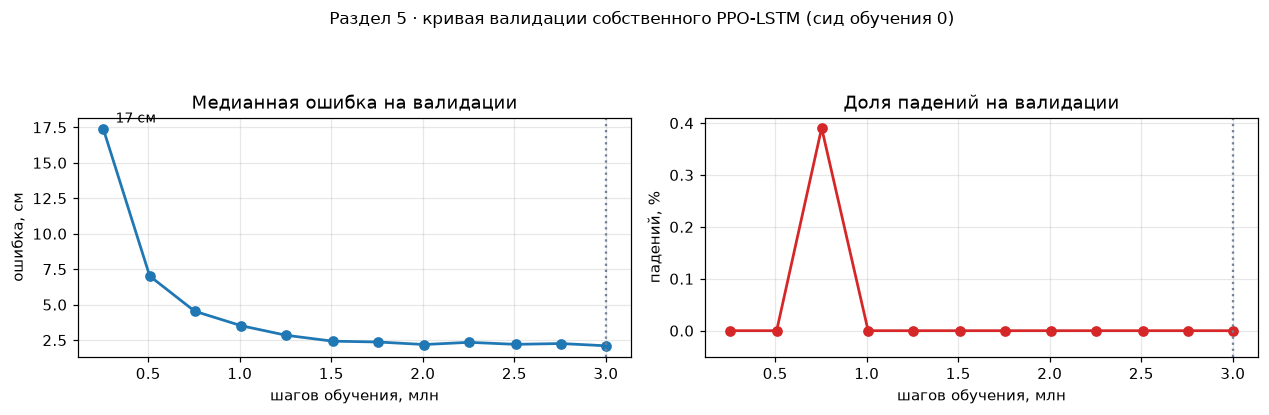

Первая проверка: 253,952 шагов, медианная ошибка 17.4 см, падений 0.0%.
Лучший чекпоинт: 3,000,000 шагов, rmse_capped = 2.31 см, падений 0.0%.


In [25]:
val = pd.read_csv(NATIVE_RUN / "val_history.csv")
best = val.loc[val.rmse_capped.idxmin()]
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11.5, 3.8))
ax0.plot(val.timesteps / 1e6, 100 * val.rmse_median, "o-", color="#1f77b4", lw=1.8)
ax0.axvline(best.timesteps / 1e6, ls=":", color="#738298")
ax0.annotate(f"{100*val.rmse_median.iloc[0]:.0f} см",
             (val.timesteps.iloc[0] / 1e6, 100 * val.rmse_median.iloc[0]),
             xytext=(8, 4), textcoords="offset points", fontsize=9)
ax0.set_title("Медианная ошибка на валидации")
ax0.set_ylabel("ошибка, см")
ax0.set_xlabel("шагов обучения, млн")
ax1.plot(val.timesteps / 1e6, 100 * val.crash_rate, "o-", color="#d62728", lw=1.8)
ax1.axvline(best.timesteps / 1e6, ls=":", color="#738298")
ax1.set_title("Доля падений на валидации")
ax1.set_ylabel("падений, %")
ax1.set_xlabel("шагов обучения, млн")
ax1.set_ylim(bottom=-0.05)
fig.suptitle("Раздел 5 · кривая валидации собственного PPO-LSTM (сид обучения 0)", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()
print(f"Первая проверка: {int(val.timesteps.iloc[0]):,} шагов, медианная ошибка "
      f"{100*val.rmse_median.iloc[0]:.1f} см, падений {100*val.crash_rate.iloc[0]:.1f}%.")
print(f"Лучший чекпоинт: {int(best.timesteps):,} шагов, rmse_capped = {100*best.rmse_capped:.2f} см, "
      f"падений {100*best.crash_rate:.1f}%.")

In [19]:
summary = pd.read_csv(root / "results" / "native_defense" / "summary.csv")
rows = []
for suite in ("test_id", "safety"):
    part = summary[summary["suite"] == suite]
    for _, r in part.iterrows():
        native = str(r["backend"]) == "native"
        method = "PPO-LSTM (свой тренер)" if native else "настроенный PID"
        label = f"{method}, сид {int(r['seed_train'])}" if native else method
        rows.append({
            "Набор": suite, "Контроллер": label, "Тренер": r["backend"],
            "Эпизодов": int(r["episodes"]),
            "Медианная ошибка, см": round(float(r["median_surviving_rmse_cm"]), 2),
            "Падений": int(r["crashes"]),
        })
display(pd.DataFrame(rows).set_index(["Набор", "Контроллер"]))
print("test_id = 200 общих условий; safety = отдельные 1000 условий на долю падений.")
print("Все строки — оценка собственного PPO-LSTM на трёх сидах и настроенного PID.")
print("Исторические числа SB3-Contrib лежат отдельно: results/defense/summary.csv.")

Тренер  Эпизодов  \
Набор   Контроллер                                          
test_id настроенный PID                baseline       200   
        PPO-LSTM (свой тренер), сид 0    native       200   
        PPO-LSTM (свой тренер), сид 1    native       200   
        PPO-LSTM (свой тренер), сид 2    native       200   
safety  настроенный PID                baseline      1000   
        PPO-LSTM (свой тренер), сид 0    native      1000   
        PPO-LSTM (свой тренер), сид 1    native      1000   
        PPO-LSTM (свой тренер), сид 2    native      1000   

                                       Медианная ошибка, см  Падений  
Набор   Контроллер                                                    
test_id настроенный PID                                2.49        0  
        PPO-LSTM (свой тренер), сид 0                  2.12        0  
        PPO-LSTM (свой тренер), сид 1                  2.22        0  
        PPO-LSTM (свой тренер), сид 2                  2.09        0  
safety  настроенный PID                                2.59        0  
        PPO-LSTM (свой тренер), сид 0                  2.14        0  
        PPO-LSTM (свой тренер), сид 1                  2.27        0  
        PPO-LSTM (свой тренер), сид 2                  2.05        0

test_id = 200 общих условий; safety = отдельные 1000 условий на долю падений.
Все строки — оценка собственного PPO-LSTM на трёх сидах и настроенного PID.
Исторические числа SB3-Contrib лежат отдельно: results/defense/summary.csv.


### Что обязательно уметь объяснить

- **Между шагами полёта** (каждые 20 мс) меняются состояния LSTM $(h_t,c_t)$ и состояние симулятора: память накапливает историю сноса и помогает отличить короткий порыв от постоянного ветра. **Веса сети при этом заморожены.**
- **Во время обучения** мы заново пропускаем сохранённые последовательности с их начальной памятью, считаем GAE и PPO loss, и градиент через время меняет уже **веса сети** $\theta$. После обновления политика выдаёт другие команды на тех же наблюдениях (раздел 4.7).
- **Критик** во время обучения видит привилегированные входы (истинный ветер, массу), актор — только 22 наблюдаемых числа. На инференсе критик не нужен.
- **Ранний агент** в разделе 1 — это **8 192 шага** (один сбор): он ещё не компенсирует ветер и падает на 3,46 с. Тот же прогресс виден численно на кривой валидации: медианная ошибка 17,4 см на 250 тыс. шагов → 2,31 см на 3 млн, 0 падений.
- **Собственный PPO-LSTM точнее PID** на общих 200 тестовых условиях: 2,12 / 2,22 / 2,09 см у трёх сидов против 2,49 см, и 0 падений из 1000 у всех четырёх контроллеров. Это результаты симуляции, для реального полёта нужны физические испытания.